<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/ECMWF_Core_Logo_RGB.png" alt="ECMWF" height="44"/>

# The hottest week of summer 2026 in France 🌡️
### Copernicus Climate Change Service · ERA5-Land · free account

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/france/heat_era5land.ipynb)

The hottest week of summer 2026 in France was **21 to 27 June**. This notebook maps its hottest hour,
**Wednesday 24 June at 16:00 in Paris (14 UTC)**, from **ERA5-Land**, the Copernicus land reanalysis at about 9 km that ECMWF
produces for the European Union. ERA5-Land covers land only, so the sea stays blank.

**What you need:** a Google account (to use Colab) and a free Copernicus account (next step). No fee, nothing to install. Everything runs on Google's computers, so a slow or mobile connection is fine.

| Data | What this notebook uses | Licence |
|---|---|---|
| [ERA5-Land hourly](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-land), about 9 km | 2 m temperature, one hour: 24 June 2026, 14 UTC | Copernicus licence, free |

**Tools:** [earthkit](https://earthkit.ecmwf.int), ECMWF's free, open-source Python tools for weather and climate data.

*Press **Runtime → Run all**. The data store queues requests, so step 2 can take a few minutes.*

> Not an official ECMWF product: a worked example for the ECMWF liaison visit to France (Météo-France, Toulouse), 2026. ERA5-Land grid values are not station measurements: check against Météo-France's own figures before quoting them.

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes a few minutes the first time.
%pip install -q "earthkit-data[cds]" earthkit-plots

## Your free Copernicus key

Copernicus data is free and open, but the data stores ask you to register once so they can manage the queue:
1. Create an account at [cds.climate.copernicus.eu](https://cds.climate.copernicus.eu) (the same login works for the
   Atmosphere Data Store).
2. Open the [dataset page](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-land?tab=download) on the Climate Data Store and accept its licence (bottom of the Download tab). You only do this once.
3. Copy your API key from your [profile page](https://cds.climate.copernicus.eu/profile) and paste it below.

**Use your own key.** Everyone who runs this notebook needs their own free Copernicus account and key. The next cell asks
for it in a hidden box and saves it on the machine running the notebook (in Colab that is a temporary machine, wiped when
you close the tab). The key is never stored in the notebook, so don't paste it into a code cell, and don't share a notebook
or screenshot that shows it. On your own computer with `~/.cdsapirc` / `~/.adsapirc` already in place, the cell asks nothing.

In [2]:
import os
from getpass import getpass
rc = {"~/.cdsapirc": "https://cds.climate.copernicus.eu/api", "~/.adsapirc": "https://ads.atmosphere.copernicus.eu/api"}
missing = [p for p in rc if not os.path.exists(os.path.expanduser(p))]
if missing:
    key = getpass("Copernicus API key: ")
    for p in missing:
        with open(os.path.expanduser(p), "w") as f:
            f.write(f"url: {rc[p]}\nkey: {key}\n")
print("Copernicus key ready")

Copernicus key ready


In [3]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import datetime as dt
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.patheffects as pe
import numpy as np

## 1 · Choose the hour and the area

In [4]:
AREA = [51.6, -5.6, 41.0, 10.0]            # north, west, south, east: metropolitan France and Corsica
YEAR, MONTH, DAY, HOUR = "2026", "06", "24", "14:00"   # UTC: 14 UTC = 16:00 in France in summer
PLACES = [("Paris", 48.857, 2.352), ("Bordeaux", 44.838, -0.579), ("Toulouse", 43.604, 1.444), ("Lyon", 45.764, 4.836),
          ("Marseille", 43.296, 5.370), ("Lille", 50.630, 3.060), ("Brest", 48.390, -4.486), ("Strasbourg", 48.573, 7.752)]

def label_places(chart, places):
    for name, la, lo in places:
        chart.scatter(x=[lo], y=[la], s=36, color="#ffd23f", edgecolors="#1a1a1a", linewidths=0.8, zorder=10)
        chart.ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
                      color="#1d2230", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

## 2 · Get ERA5-Land

In [5]:
era = ekd.from_source("cds", "reanalysis-era5-land", {
    "variable": "2m_temperature", "year": YEAR, "month": MONTH, "day": DAY, "time": HOUR,
    "area": AREA, "data_format": "grib"}).to_xarray()
t2m = era[list(era.data_vars)[0]].squeeze() - 273.15
print(f"{float(t2m.min()):.0f} to {float(t2m.max()):.0f} °C across the land")
for n, la, lo in PLACES:
    print(f"  {n:11s} {float(t2m.sel(latitude=la, longitude=lo, method='nearest')):5.1f} °C")

11 to 43 °C across the land
  Paris        38.0 °C
  Bordeaux     40.6 °C
  Toulouse     38.8 °C
  Lyon         35.4 °C
  Marseille    31.5 °C
  Lille        34.8 °C
  Brest        31.5 °C
  Strasbourg   34.8 °C


## 3 · Map it

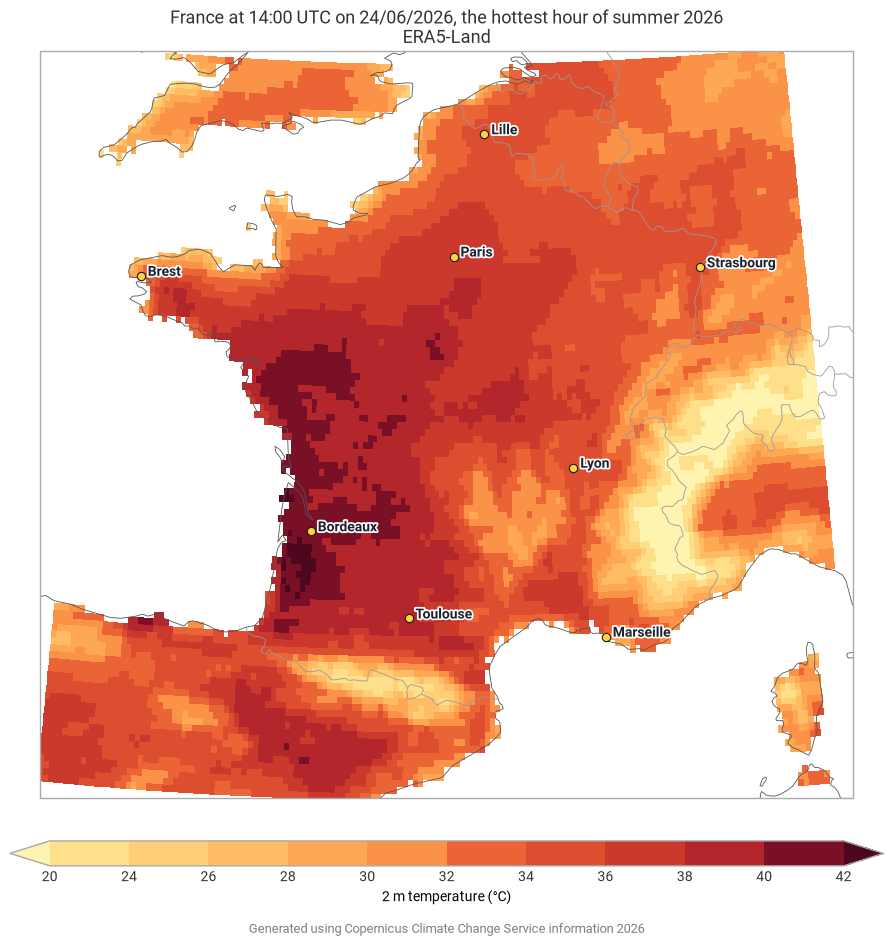

In [6]:
colors = ["#fff3b0", "#ffe08a", "#ffc46b", "#ffa552", "#f6823f", "#e85d33", "#cf3a2c", "#a81f2a", "#7a1026", "#4d0820"]
style = ekp.styles.Style(levels=[20, 24, 26, 28, 30, 32, 34, 36, 38, 40, 42], colors=colors, extend="both")
chart = ekp.Map(domain=[AREA[1], AREA[3], AREA[2], AREA[0]], figsize=(11, 9))
chart.pcolormesh(t2m, style=style)          # grid cells, about 9 km
chart.coastlines(linewidth=0.6); chart.borders(linewidth=0.6)
label_places(chart, PLACES)
chart.legend(label="2 m temperature (°C)")
chart.title(f"France at {HOUR} UTC on {DAY}/{MONTH}/{YEAR}, the hottest hour of summer 2026\nERA5-Land", fontsize=13)
chart.attribution("Generated using Copernicus Climate Change Service information 2026")
chart.save("heat_era5land.png")
chart.show()

## 4 · Your turn 🌍

- **The night after:** `DAY, HOUR = "25", "04:00"`: which cities stay warm all night?
- **The hottest grid cell of the week:** `DAY, HOUR = "22", "15:00"` (the Landes, south of Bordeaux).
- **Another summer:** change `YEAR`, for example `"2019"` (the June 2019 heatwave). ERA5-Land goes back to 1950.
- **Feels-like heat:** add `"2m_dewpoint_temperature"` and compute the heat index with earthkit-meteo.

### Data & licence
Copernicus data is free and open under the Copernicus licence (CC-BY 4.0). Credit:
*Generated using Copernicus Climate Change Service information 2026.* ECMWF runs the Copernicus Atmosphere Monitoring Service and the
Copernicus Climate Change Service for the European Union.

[Climate Data Store](https://cds.climate.copernicus.eu) · [Atmosphere Data Store](https://ads.atmosphere.copernicus.eu) ·
[earthkit](https://earthkit.ecmwf.int)